In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from torchgeo_bench.coordbench.spatiotemporal_idw import (
    find_knn_and_predict, time_normalized, time_to_normalized_time_of_year,
    time_to_normalized_year, time_of_year_and_year)

In [2]:
KS = (5, 20)

In [3]:
rng = np.random.default_rng(0)

In [4]:
from sklearn.metrics import r2_score
from torchgeo_bench.coordbench.datasets import (
    load_daily_usa_electric_usage, load_era5_ecmwf, load_chelsa_monthly)

## Prep with random split

In [5]:
def prep(b, target, subsample_N=None, group=None):
    valid = np.where((b.lat >= -60) & np.isfinite(b.tasks[target]))[0]

    num_samples = min(subsample_N, len(valid)) if subsample_N is not None else len(valid)
    idx = rng.choice(valid, num_samples, replace=False)

    lat, lon, t = b.lat[idx], b.lon[idx], b.posix_timestamp[idx]

    if group is None:  # one group per unique location
        group = np.unique(np.c_[lat, lon], axis=0, return_inverse=True)[1].ravel()
    else:
        group = group[idx]

    # random test split for now...
    test_g = rng.choice(np.unique(group), len(np.unique(group)) // 5, replace=False)
    test = np.isin(group, test_g)

    return dict(name=b.name, lat=lat, lon=lon, t=t,
                tasks={target: b.tasks[target][idx]}, test=test)

In [6]:
elec = load_daily_usa_electric_usage(subsample_locations=True)[0]
era5 = load_era5_ecmwf(subsample_locations=True)[0]
chelsa = load_chelsa_monthly(subsample_locations=True)[0]

/u/lbetti/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: invalid value encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))


In [7]:
data = (
    [prep(elec, t, group=elec.spatial_aggregation_key[1].to_numpy(), subsample_N=None) for t in elec.tasks]
    + [prep(era5, "t2m", subsample_N=None)]
    + [prep(chelsa, "hurs", subsample_N=None)]
)

## Functions for running IDW

In [8]:
def run_idw(d, time_fn, time_name, cs, ks=KS, device="cuda"):
    """R² on d's test split for every task, c and k, using one time_fn."""
    tr, te = ~d["test"], d["test"]
    rows = []
    for task, y in d["tasks"].items():
        for c in cs:
            p = find_knn_and_predict(
                d["lat"][tr], d["lon"][tr], d["t"][tr], y[tr],
                d["lat"][te], d["lon"][te], d["t"][te],
                ks, "regression", 0, c, device=device, time_fn=time_fn)
            rows += [dict(dataset=d["name"], task=task, time_fn=time_name, k=k, c=c,
                          r2=r2_score(y[te], p[k])) for k in ks]
    return rows

In [9]:
def compare_time_fns(data, time_fns, **kw):
    """time_fns: {name: (time_fn, cs)}. Returns one long DataFrame."""
    return pd.DataFrame([r for d in data for name, (fn, cs) in time_fns.items()
                         for r in run_idw(d, fn, name, cs, **kw)])

In [10]:
def best_c(df):
    """Best R² over c, per (dataset, task) x (time_fn, k)."""
    return (df.groupby(["dataset", "task", "time_fn", "k"]).r2.max()
              .unstack(["time_fn", "k"]).round(3))

## Define time fns and Cs to iterate over

In [11]:
TIME_FNS = {
    "raw": (None, (0.0, 1e-10, 0.01, 1, 1e4, 1e6, 1e8)),  # seconds
    "norm": (time_normalized, (0.0, 1e-10, 0.01, 1, 1e4, 1e6, 1e8)),
    "time_of_year": (time_to_normalized_time_of_year, (0.0, 1e-10, 0.01, 1, 1e4, 1e6, 1e8)),
    "year": (time_to_normalized_year, (0.0, 1e-10, 0.01, 1, 1e4, 1e6, 1e8)),
    "toy+year": (time_of_year_and_year, (0.0, 1e-10, 0.01, 1, 1e4, 1e6, 1e8)),
}


In [12]:
res = compare_time_fns(data, TIME_FNS)
print(best_c(res))

/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/spatiotemporal_idw.py:30: RuntimeWarning: invalid value encountered in divide
  return (year - min_year) / (max_year - min_year)  # Normalize to [0, 1]
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/spatiotemporal_idw.py:30: RuntimeWarning: invalid value encountered in divide
  return (year - min_year) / (max_year - min_year)  # Normalize to [0, 1]
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/spatiotemporal_idw.py:30: RuntimeWarning: invalid value encountered in divide
  return (year - min_year) / (max_year - min_year)  # Normalize to [0, 1]
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/spatiotemporal_idw.py:30: RuntimeWarning: invalid value encountered in divide
  return (year - min_year) / (max_year - min_year)  # Normalize to [0, 1]
/u/lbetti/projects/torchgeo-bench/src/torchgeo_bench/coordbench/spatiotemporal_idw.py:30: RuntimeWarning: invalid value encountered in d

time_fn                                                 norm           raw  \
k                                                         5      20     5    
dataset                                    task                              
chelsa                                     hurs        0.923  0.906  0.867   
era5_ecmwf                                 t2m         0.980  0.978  0.974   
usa_daily_electric_load_2016_from_centroid median     -1.466 -0.404 -0.336   
                                           median_log  0.316  0.360  0.105   

time_fn                                                      time_of_year  \
k                                                         20           5    
dataset                                    task                             
chelsa                                     hurs        0.812        0.859   
era5_ecmwf                                 t2m         0.971        0.980   
usa_daily_electric_load_2016_from_centroid median     -0.094       -

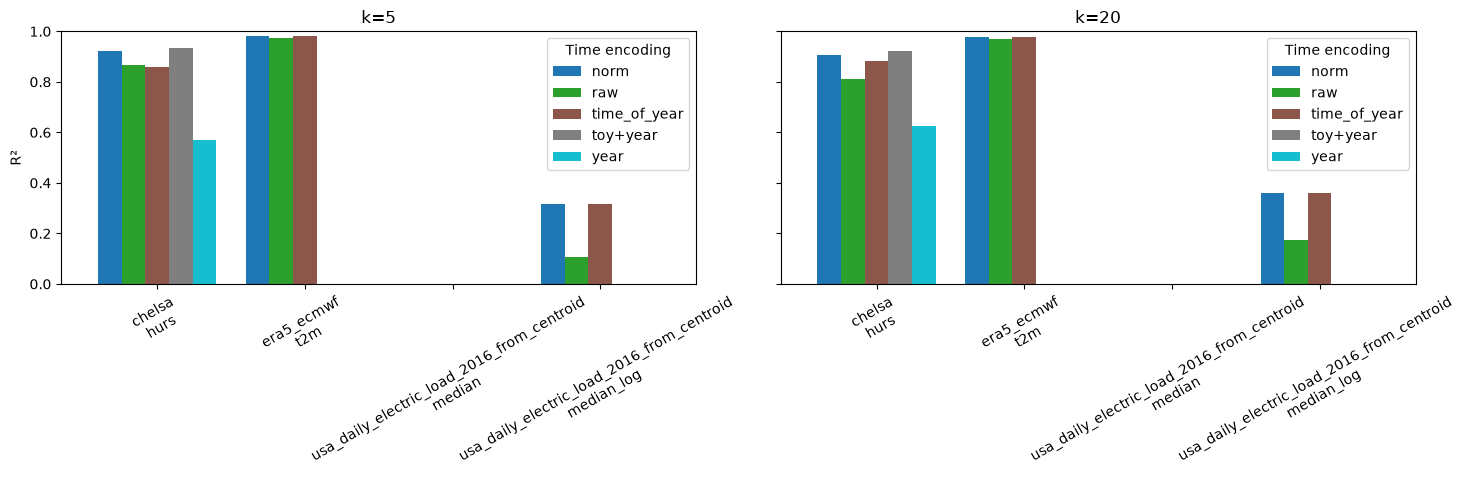

In [14]:
import matplotlib.pyplot as plt

df = best_c(res).clip(lower=0)
df.index = df.index.map(lambda x: f"{x[0]}\n{x[1]}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, k in zip(axes, [5, 20]):
    df.xs(k, axis=1, level="k").plot.bar(ax=ax, width=0.8, colormap="tab10")
    ax.set(title=f"k={k}", xlabel="", ylabel="R²", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Time encoding")

plt.tight_layout()
plt.show()